# Fraud Detection & Anomaly Detection — Industry-Style ML Project

**Purpose:** learn how to design, evaluate, and operationalize a fraud detection system, with emphasis on rare events, false-positive costs, time-aware validation, delayed labels, and serving.

This is a **portfolio project using a public benchmark dataset**, not a claim that this system was deployed at an employer. The public dataset is anonymized and synthetic-like in important ways; it does not fully represent a bank's real-time decision environment.

## How to use this notebook

- Run cells from top to bottom in a fresh kernel.
- Read the reasoning before running code.
- Do not report metrics until you have run the notebook and recorded actual outputs.
- Treat costs in examples as illustrative unless you replace them with justified business values.
- Use the Python repository for reusable production code; use this notebook to learn and explain decisions.

## The agreed 12-step framework

1. Business problem and requirements
2. Data collection, quality, and lineage
3. EDA and feature engineering/preprocessing
4. Baseline and model development
5. Evaluation and error analysis
6. Reproducibility and model management
7. ML-specific testing and quality gates
8. Deployment and serving
9. Production monitoring
10. Operations and continuous improvement
11. Performance, cost, privacy, and security
12. Documentation and interview readiness

The same 12 steps are used as in Project 1, but the contents are adapted to fraud detection.

# STEP 1 — Business problem and requirements

## 1.1 Define the decision, not just the model

A payment fraud model estimates whether a transaction is suspicious. The system then decides what to do with the score:
- approve;
- send for additional verification;
- hold for review;
- decline.

These actions have different costs. A false negative may allow fraud; a false positive may block a legitimate customer and damage trust. There is usually no single threshold that is best for every channel, customer segment, or transaction value.

### Problem definition for this portfolio

- **Prediction unit:** one transaction at authorization time.
- **Target:** whether the transaction is labelled fraudulent.
- **Positive class:** fraud (`1`).
- **Model outputs:** risk score/probability and an action based on a threshold.
- **Primary offline metric:** average precision, alongside precision, recall, and recall at a defined review capacity.
- **Operational metrics:** latency, throughput, timeout/error rate, and review queue size.
- **Business metric:** net fraud loss avoided after intervention costs, not just classification accuracy.

## 1.2 Key constraints

- Fraud is rare, so class imbalance is expected.
- Labels may arrive after investigation or chargeback.
- Transaction behavior changes over time.
- Prediction must use only information available at the decision timestamp.
- Review teams have limited capacity.
- A score is not proof that a person committed fraud.

### Interview question

**Why can a model with 99.8% accuracy be useless?** If fraud prevalence is 0.2%, predicting every transaction as legitimate achieves 99.8% accuracy while detecting zero fraud.

# STEP 2 — Data collection, quality, and lineage

## 2.1 Dataset and limitations

We use the public Credit Card Fraud Detection dataset hosted by the `mlegit` GitHub repository. It contains anonymized transaction features, `Time`, `Amount`, and `Class` (1 = fraud). The original benchmark is highly imbalanced.

The source is a public mirror; availability and licensing terms should be checked before redistribution. For a real project, record the source URL, retrieval date, checksum, license, schema version, and access permissions. Do not use a benchmark result as evidence of production performance.

## 2.2 Data contract

Expected columns:
- `Time`: elapsed seconds from the first transaction in the dataset (not a wall-clock timestamp).
- `Amount`: transaction amount in the dataset's units.
- `V1` ... `V28`: anonymized transformed features.
- `Class`: target label.

The `Time` column enables an ordered split, but it is **not a real calendar timestamp**. The anonymized `V` features limit interpretability and realistic feature engineering.

In [1]:
from __future__ import annotations

import hashlib
import json
import os
import platform
import sys
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import IsolationForest, RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, brier_score_loss, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score,
    roc_auc_score, precision_recall_curve, RocCurveDisplay,
    PrecisionRecallDisplay
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# NumPy 2.x on Apple Silicon (Accelerate BLAS) emits spurious
# "divide by zero / overflow / invalid value encountered in matmul" warnings
# even on clean, finite data. Results are correct, so silence only these.
warnings.filterwarnings("ignore", message=r".*encountered in matmul", category=RuntimeWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme()

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("Run started (UTC):", datetime.now(timezone.utc).isoformat())

Python: 3.10.20
Platform: macOS-26.7.1-arm64-arm-64bit
pandas: 2.3.3
scikit-learn: 1.7.2
Run started (UTC): 2026-10-14T10:08:54.010667+00:00


In [2]:
DATA_URL = (
    "https://raw.githubusercontent.com/nsethi31/Kaggle-Data-Credit-Card-Fraud-Detection/master/creditcard.csv"
)
DATA_DIR = Path("data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)
DATA_PATH = DATA_DIR / "creditcard.csv"

if DATA_PATH.exists():
    df_raw = pd.read_csv(DATA_PATH)
    print(f"Loaded cached dataset from {DATA_PATH}")
else:
    try:
        df_raw = pd.read_csv(DATA_URL)
        df_raw.to_csv(DATA_PATH, index=False)
        print(f"Downloaded and cached dataset at {DATA_PATH}")
    except Exception as exc:
        raise RuntimeError(
            "Dataset download failed. Check connectivity and the source URL, or place "
            "the CSV manually at data/raw/creditcard.csv."
        ) from exc

print("Shape:", df_raw.shape)
display(df_raw.head())

Loaded cached dataset from data/raw/creditcard.csv
Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2.3 Schema, duplicates, missingness, and target validation

Validate the received data rather than assuming the source has not changed. In production, these checks should be automated and should stop training when critical assumptions fail.

In [3]:
required = {"Time", "Amount", "Class"}
missing = required - set(df_raw.columns)
assert not missing, f"Missing required columns: {sorted(missing)}"
assert len(df_raw) > 0, "Dataset is empty"
assert df_raw["Class"].notna().all(), "Target has missing values"
assert set(df_raw["Class"].unique()).issubset({0, 1}), "Unexpected target labels"

df = df_raw.copy()
df["Class"] = df["Class"].astype("int8")

print("Duplicate full rows:", int(df.duplicated().sum()))
print("Missing values by column (top 10):")
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame("missing_count"))
print("Target counts:")
display(df["Class"].value_counts().rename(index={0: "legitimate", 1: "fraud"}).to_frame("count"))
print("Fraud prevalence:", f"{df['Class'].mean():.6%}")
display(df[["Time", "Amount"]].describe().T)

Duplicate full rows: 1081
Missing values by column (top 10):


,missing_count
Time,0
V16,0
Amount,0
V28,0
V27,0
V26,0
V25,0
V24,0
V23,0
V22,0


Target counts:


,count
Class,
legitimate,284315
fraud,492


Fraud prevalence: 0.172749%


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.859575,47488.145955,0.0,54201.5,84692.0,139320.500,172792.00
Amount,284807.0,88.349619,250.120109,0.0,5.6,22.0,77.165,25691.16


## 2.4 Data leakage and point-in-time correctness

The central question is: **would this feature have been available when the transaction was being authorized?**

Leakage examples:
- a chargeback outcome recorded after the transaction;
- investigation notes created after an alert;
- features computed using future transactions;
- target-derived aggregates that include the current transaction's eventual label.

The dataset's anonymized features are pre-transformed, and their full production lineage is not provided. We can demonstrate time-ordered evaluation, but we cannot certify real-world point-in-time correctness from this benchmark alone.

# STEP 3 — EDA and feature engineering/preprocessing

## 3.1 Explore the target and transaction values

For fraud, class prevalence and the cost of errors matter more than a simple accuracy score. Examine the target distribution and transaction amount distribution. Extreme values can be legitimate, fraudulent, or data-quality issues; do not remove them just because they are outliers.

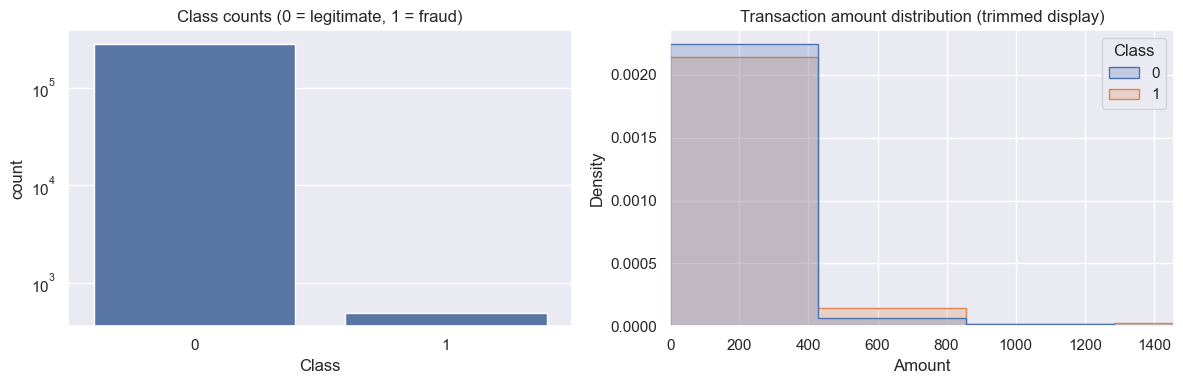

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="Class", ax=axes[0])
axes[0].set_title("Class counts (0 = legitimate, 1 = fraud)")
axes[0].set_yscale("log")
sns.histplot(data=df, x="Amount", hue="Class", bins=60, stat="density",
             common_norm=False, element="step", ax=axes[1])
axes[1].set_xlim(0, df["Amount"].quantile(0.995))
axes[1].set_title("Transaction amount distribution (trimmed display)")
plt.tight_layout()
plt.show()

In [5]:
# Time is elapsed seconds in this dataset, not a real date/time.
df["time_bin"] = pd.qcut(df["Time"], q=10, duplicates="drop")
time_fraud = df.groupby("time_bin", observed=False)["Class"].agg(["mean", "sum", "count"])
time_fraud = time_fraud.rename(columns={"mean": "fraud_rate", "sum": "fraud_count", "count": "transactions"})
display(time_fraud)

,fraud_rate,fraud_count,transactions
time_bin,,,
"(-0.001, 35027.0]",0.003265,93,28482
"(35027.0, 47694.2]",0.002247,64,28480
"(47694.2, 60776.0]",0.001650,47,28483
"(60776.0, 73261.4]",0.001299,37,28478
"(73261.4, 84692.0]",0.000983,28,28481
"(84692.0, 120396.0]",0.003195,91,28484
"(120396.0, 132929.0]",0.000843,24,28480
"(132929.0, 145247.8]",0.001159,33,28477
"(145247.8, 157640.4]",0.001861,53,28481


## 3.2 Feature decisions and preprocessing

The `V1`–`V28` variables are already transformed/anonymized. `Time` and `Amount` have different scales, so standardization is reasonable for Logistic Regression and distance-based methods. Tree models usually do not require scaling, but including preprocessing in the pipeline keeps the workflow reproducible.

We will:
- exclude `Class` from features;
- retain `Time` for ordered evaluation and as a predictor in this demonstration;
- scale all numeric inputs inside the pipeline;
- use only training data to fit preprocessing.

In a real-time system, feature transformations must match the serving contract. A model trained on historical `Time` patterns may not generalize when time patterns shift, so assess whether `Time` is appropriate and whether a rolling time feature is needed.

In [6]:
TARGET = "Class"
X = df.drop(columns=[TARGET, "time_bin"], errors="ignore").copy()
y = df[TARGET].astype(int)
feature_columns = X.columns.tolist()

assert TARGET not in X.columns
assert X.index.equals(y.index)
print("Feature count:", X.shape[1])
print("Features:", feature_columns[:8], "...")

Feature count: 30
Features: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7'] ...


## 3.3 Use a time-ordered train/validation/test split

Random splits can leak temporal patterns when transactions from the future are mixed into training. Here, we sort by the dataset's `Time` and use:
- earliest 60% for training;
- next 20% for validation;
- latest 20% for final testing.

This simulates forward-in-time evaluation better than a random split. It is still only an approximation: the benchmark lacks real dates, and transactions may have dependence or repeated entities not represented in the schema.

In [7]:
ordered = df.sort_values("Time", kind="stable").index
n = len(ordered)
train_end = int(n * 0.60)
valid_end = int(n * 0.80)

train_idx = ordered[:train_end]
valid_idx = ordered[train_end:valid_end]
test_idx = ordered[valid_end:]

X_train, y_train = X.loc[train_idx], y.loc[train_idx]
X_valid, y_valid = X.loc[valid_idx], y.loc[valid_idx]
X_test, y_test = X.loc[test_idx], y.loc[test_idx]

split_summary = pd.DataFrame({
    "rows": [len(X_train), len(X_valid), len(X_test)],
    "fraud_count": [int(y_train.sum()), int(y_valid.sum()), int(y_test.sum())],
    "fraud_rate": [float(y_train.mean()), float(y_valid.mean()), float(y_test.mean())],
    "time_min": [df.loc[train_idx, "Time"].min(), df.loc[valid_idx, "Time"].min(), df.loc[test_idx, "Time"].min()],
    "time_max": [df.loc[train_idx, "Time"].max(), df.loc[valid_idx, "Time"].max(), df.loc[test_idx, "Time"].max()]
}, index=["train", "validation", "test"])
display(split_summary)

assert X_train.index.max() < X_valid.index.min()
assert X_valid.index.max() < X_test.index.min()

,rows,fraud_count,fraud_rate,time_min,time_max
train,170884,360,0.002107,0.0,120396.0
validation,56961,57,0.001001,120396.0,145247.0
test,56962,75,0.001317,145248.0,172792.0


In [8]:
preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
print("Preprocessing: median imputation + standardization, fit only on training folds.")

Preprocessing: median imputation + standardization, fit only on training folds.


### Interview checkpoints for Step 3

- Why should we not scale before splitting? It lets validation/test distribution influence fitted transformation parameters.
- Why use a temporal split? It better simulates predicting future transactions from past data.
- Why not remove outliers automatically? Fraud can be rare/extreme by nature; outlier removal may remove the signal.
- What is point-in-time correctness? Each feature must be computed only from information available at prediction time.

# STEP 4 — Baseline and model development

## 4.1 Baseline: predict the majority class

A baseline establishes how little a trivial system can accomplish. With extreme imbalance, the majority-class classifier can have excellent accuracy but zero fraud recall.

In [9]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
base_pred = baseline.predict(X_valid)
base_proba = baseline.predict_proba(X_valid)[:, 1] if len(baseline.classes_) == 2 else np.zeros(len(X_valid))

baseline_summary = {
    "accuracy": float((base_pred == y_valid).mean()),
    "fraud_precision": float(precision_score(y_valid, base_pred, zero_division=0)),
    "fraud_recall": float(recall_score(y_valid, base_pred, zero_division=0)),
    "fraud_count_detected": int(((base_pred == 1) & (y_valid.to_numpy() == 1)).sum())
}
display(pd.Series(baseline_summary, name="majority baseline").to_frame())

,majority baseline
accuracy,0.998999
fraud_precision,0.000000
fraud_recall,0.000000
fraud_count_detected,0.000000


## 4.2 Supervised model candidates

We compare:
- **Logistic Regression with class weights:** a simple, regularized baseline; coefficients can be inspected, but relationships are linear in the transformed features.
- **Random Forest with class weights:** captures nonlinear interactions; can be larger and slower.
- **Extra Trees with class weights:** randomized tree splits can provide a strong ensemble baseline.
- **Histogram Gradient Boosting:** sequentially fits trees to correct errors. It does not expose `class_weight` in all scikit-learn versions, so we demonstrate it with sample weights to handle class imbalance.

We use `average_precision` as the main ranking metric. Model choice should also account for time split, precision/recall at operational thresholds, stability, latency, and interpretability.

In [10]:
from sklearn.utils.class_weight import compute_sample_weight

models = {
    "LogisticRegression_balanced": LogisticRegression(
        max_iter=2000, class_weight="balanced", solver="lbfgs", random_state=RANDOM_STATE
    ),
    "RandomForest_balanced": RandomForestClassifier(
        n_estimators=250, min_samples_leaf=2, class_weight="balanced_subsample",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "ExtraTrees_balanced": ExtraTreesClassifier(
        n_estimators=250, min_samples_leaf=2, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
}

# HistGradientBoosting is trained separately below with sample weights.
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
fitted_models = {}

for name, estimator in models.items():
    pipe = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", clone(estimator))
    ])
    scores = cross_validate(
        pipe, X_train, y_train, cv=cv,
        scoring={"ap": "average_precision", "roc_auc": "roc_auc"},
        n_jobs=1, return_train_score=False
    )
    cv_rows.append({
        "model": name,
        "cv_average_precision_mean": scores["test_ap"].mean(),
        "cv_average_precision_std": scores["test_ap"].std(),
        "cv_roc_auc_mean": scores["test_roc_auc"].mean()
    })
    fitted_models[name] = pipe

cv_results = pd.DataFrame(cv_rows).sort_values("cv_average_precision_mean", ascending=False)
display(cv_results)

,model,cv_average_precision_mean,cv_average_precision_std,cv_roc_auc_mean
2,ExtraTrees_balanced,0.867448,0.014817,0.972165
1,RandomForest_balanced,0.860763,0.015725,0.960477
0,LogisticRegression_balanced,0.765681,0.050566,0.975155


## 4.3 Fit the candidate models and compare on validation

Cross-validation is useful for estimating performance on training-period data, but a future validation window is especially relevant for this time-dependent problem. We fit the candidates on the training period and compare ranking metrics on the later validation period.

Class weights change the learning objective; they do not magically create new fraud examples and do not guarantee calibrated probabilities. Thresholds and calibration must be evaluated separately.

In [11]:
validation_rows = []
for name, pipe in fitted_models.items():
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_valid)[:, 1]
    validation_rows.append({
        "model": name,
        "validation_average_precision": average_precision_score(y_valid, proba),
        "validation_roc_auc": roc_auc_score(y_valid, proba),
        "validation_brier": brier_score_loss(y_valid, proba)
    })

validation_results = pd.DataFrame(validation_rows).sort_values(
    "validation_average_precision", ascending=False
).reset_index(drop=True)
display(validation_results)

best_name = validation_results.loc[0, "model"]
model = fitted_models[best_name]
valid_proba = model.predict_proba(X_valid)[:, 1]
print("Selected candidate:", best_name)

,model,validation_average_precision,validation_roc_auc,validation_brier
0,LogisticRegression_balanced,0.771877,0.970927,0.028161
1,ExtraTrees_balanced,0.765482,0.936029,0.000366
2,RandomForest_balanced,0.760447,0.967836,0.000388


Selected candidate: LogisticRegression_balanced


## 4.4 Unsupervised anomaly detection: Isolation Forest

Supervised models learn from labelled fraud examples. Anomaly detection can identify unusual transactions without requiring every transaction to have a fraud label, which is useful when labels are scarce or delayed. But unusual does not automatically mean fraudulent.

Isolation Forest isolates observations using randomized trees. Points that are easier to isolate tend to receive more anomalous scores. Its `contamination` setting influences the decision boundary for its built-in prediction, but it should not be treated as a known fraud prevalence or an optimal business threshold.

We fit the detector on training transactions and inspect how its anomaly score ranks fraud in the validation period. The fraud labels are used for evaluation, not fitting.

In [12]:
iso = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", IsolationForest(
        n_estimators=250,
        contamination="auto",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])
iso.fit(X_train)

# IsolationForest decision_function: lower means more anomalous.
# Negate it so larger scores mean "more anomalous" for average_precision_score.
iso_valid_score = -iso.decision_function(X_valid)
iso_valid_ap = average_precision_score(y_valid, iso_valid_score)
iso_valid_auc = roc_auc_score(y_valid, iso_valid_score)

print("Isolation Forest validation average precision:", round(float(iso_valid_ap), 6))
print("Isolation Forest validation ROC-AUC:", round(float(iso_valid_auc), 6))
print("Interpretation: this evaluates anomaly ranking, not a calibrated fraud probability.")

Isolation Forest validation average precision: 0.022537
Isolation Forest validation ROC-AUC: 0.931589
Interpretation: this evaluates anomaly ranking, not a calibrated fraud probability.


### Supervised versus unsupervised — interview comparison

| Dimension | Supervised classifier | Anomaly detector |
|---|---|---|
| Training signal | Historical fraud labels | Structure of feature distribution |
| Strength | Learns patterns associated with known fraud | Can surface unusual patterns without complete labels |
| Weakness | Label delay, imbalance, new fraud patterns | Legitimate rare behavior can look anomalous |
| Output | Often a probability/score | Usually an anomaly score |
| Evaluation | Label-based classification metrics | Label-based ranking metrics if labels exist |
| Typical use | Primary decision model when labels are usable | Candidate generator, secondary signal, or cold-start support |

A hybrid system may combine signals, but complexity should be justified by measured gains.

# STEP 5 — Evaluation and error analysis

## 5.1 Why average precision and precision-recall matter

With rare positives, ROC-AUC can look strong even when the model produces too many false alerts. Average precision and the precision-recall curve focus more directly on the positive class. Always compare average precision to the **positive prevalence**: a random ranking has expected average precision roughly around the positive fraction.

Precision answers: among flagged transactions, how many were fraud?
Recall answers: among fraud transactions, how many did we flag?

Validation fraud prevalence (random-ranking reference): 0.001001
Validation AP: 0.771877


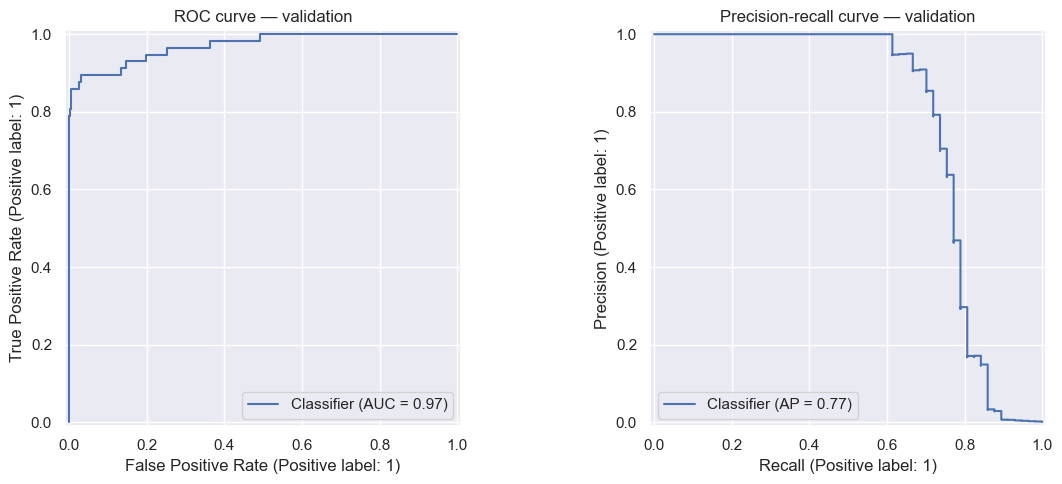

In [13]:
print("Validation fraud prevalence (random-ranking reference):", round(float(y_valid.mean()), 6))
print("Validation AP:", round(float(average_precision_score(y_valid, valid_proba)), 6))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_valid, valid_proba, ax=axes[0])
PrecisionRecallDisplay.from_predictions(y_valid, valid_proba, ax=axes[1])
axes[0].set_title("ROC curve — validation")
axes[1].set_title("Precision-recall curve — validation")
plt.tight_layout()
plt.show()

## 5.2 Threshold selection: business costs and review capacity

The model score is not the final action. A lower threshold usually catches more fraud but flags more legitimate transactions. The threshold should reflect:
- fraud loss avoided;
- false-positive customer harm;
- manual-review capacity;
- intervention effectiveness;
- transaction amount and channel;
- regulatory and policy constraints.

For illustration, we use a simple cost function: false negatives cost 10 units and false positives cost 1 unit. These are **invented teaching assumptions**, not empirical values. In a real setting, expected cost may vary by transaction amount, and a review action can have a different cost than an automatic decline.

We select a threshold using validation data only; test data remains untouched until final evaluation.

In [14]:
FN_COST = 10.0  # illustrative cost units for missed fraud
FP_COST = 1.0   # illustrative cost units for a false alert

def cost_at_threshold(y_true, scores, threshold, fn_cost=FN_COST, fp_cost=FP_COST):
    truth = np.asarray(y_true).astype(int)
    pred = (np.asarray(scores) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(truth, pred, labels=[0, 1]).ravel()
    return {
        "threshold": float(threshold),
        "cost": float(fn_cost * fn + fp_cost * fp),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "precision": float(precision_score(truth, pred, zero_division=0)),
        "recall": float(recall_score(truth, pred, zero_division=0)),
        "f1": float(f1_score(truth, pred, zero_division=0))
    }

threshold_table = pd.DataFrame([
    cost_at_threshold(y_valid, valid_proba, t)
    for t in np.linspace(0.01, 0.99, 99)
])
best_threshold = float(threshold_table.loc[threshold_table["cost"].idxmin(), "threshold"])
print("Selected validation threshold:", round(best_threshold, 3))
display(threshold_table.sort_values("cost").head(10))

Selected validation threshold: 0.99


,threshold,cost,tn,fp,fn,tp,precision,recall,f1
98,0.99,180.0,56854,50,13,44,0.468085,0.771930,0.582781
97,0.98,186.0,56838,66,12,45,0.405405,0.789474,0.535714
96,0.97,212.0,56812,92,12,45,0.328467,0.789474,0.463918
95,0.96,224.0,56790,114,11,46,0.287500,0.807018,0.423963
94,0.95,249.0,56765,139,11,46,0.248649,0.807018,0.380165
93,0.94,272.0,56742,162,11,46,0.221154,0.807018,0.347170
92,0.93,296.0,56718,186,11,46,0.198276,0.807018,0.318339
91,0.92,324.0,56690,214,11,46,0.176923,0.807018,0.290221
90,0.91,331.0,56673,231,10,47,0.169065,0.824561,0.280597
89,0.90,335.0,56659,245,9,48,0.163823,0.842105,0.274286


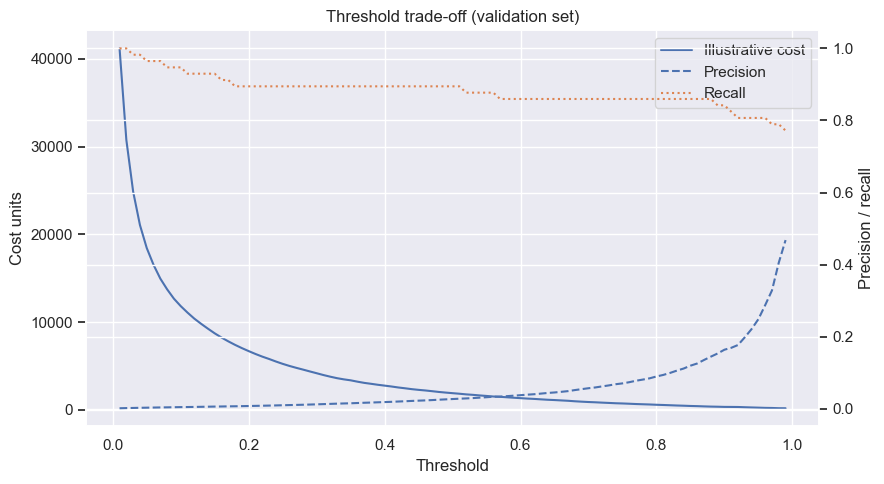

In [15]:
fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(threshold_table["threshold"], threshold_table["cost"], label="Illustrative cost")
ax1.set_xlabel("Threshold")
ax1.set_ylabel("Cost units")
ax1.set_title("Threshold trade-off (validation set)")
ax2 = ax1.twinx()
ax2.plot(threshold_table["threshold"], threshold_table["precision"], linestyle="--", label="Precision")
ax2.plot(threshold_table["threshold"], threshold_table["recall"], linestyle=":", label="Recall")
ax2.set_ylabel("Precision / recall")
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")
plt.tight_layout()
plt.show()

## 5.3 Capacity-based evaluation

A fraud team may be able to investigate only the top N transactions per hour/day. In that case, a top-K metric or recall at a fixed alert volume can be more operationally useful than a global threshold.

The example below computes recall and precision among the highest-scored `k` transactions. Choose `k` from a realistic operations capacity; the demonstration uses 1% of the validation sample.

In [16]:
def top_k_metrics(y_true, scores, fraction=0.01):
    y_arr = np.asarray(y_true).astype(int)
    score_arr = np.asarray(scores)
    k = max(1, int(np.ceil(len(y_arr) * fraction)))
    top_idx = np.argsort(score_arr)[-k:]
    flagged = np.zeros(len(y_arr), dtype=bool)
    flagged[top_idx] = True
    tp = int(((y_arr == 1) & flagged).sum())
    total_fraud = int((y_arr == 1).sum())
    return {
        "k": k,
        "flagged_fraction": k / len(y_arr),
        "precision_at_k": tp / k,
        "recall_at_k": tp / max(total_fraud, 1),
        "fraud_found": tp,
        "total_fraud": total_fraud
    }

display(pd.Series(top_k_metrics(y_valid, valid_proba, fraction=0.01)).to_frame("top 1% validation"))

,top 1% validation
k,570.000000
flagged_fraction,0.010007
precision_at_k,0.085965
recall_at_k,0.859649
fraud_found,49.000000
total_fraud,57.000000


## 5.4 Final held-out test evaluation

Once the model and threshold are fixed, evaluate them on the latest test window. Do not keep tuning against this test set. If test-set findings drive a model change, you have effectively used the test set during development and need a fresh evaluation window.

In [17]:
test_proba = model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= best_threshold).astype(int)

test_metrics = {
    "selected_model": best_name,
    "threshold": best_threshold,
    "fraud_prevalence": float(y_test.mean()),
    "accuracy": float((test_pred == y_test.to_numpy()).mean()),
    "precision": float(precision_score(y_test, test_pred, zero_division=0)),
    "recall": float(recall_score(y_test, test_pred, zero_division=0)),
    "f1": float(f1_score(y_test, test_pred, zero_division=0)),
    "average_precision": float(average_precision_score(y_test, test_proba)),
    "roc_auc": float(roc_auc_score(y_test, test_proba)),
    "brier_score": float(brier_score_loss(y_test, test_proba))
}
display(pd.Series(test_metrics, name="held-out future test").to_frame())
print(classification_report(y_test, test_pred, target_names=["Legitimate", "Fraud"], zero_division=0))

,held-out future test
selected_model,LogisticRegression_balanced
threshold,0.99
fraud_prevalence,0.001317
accuracy,0.998771
precision,0.522124
recall,0.786667
f1,0.62766
average_precision,0.743626
roc_auc,0.982026
brier_score,0.022732


              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56887
       Fraud       0.52      0.79      0.63        75

    accuracy                           1.00     56962
   macro avg       0.76      0.89      0.81     56962
weighted avg       1.00      1.00      1.00     56962



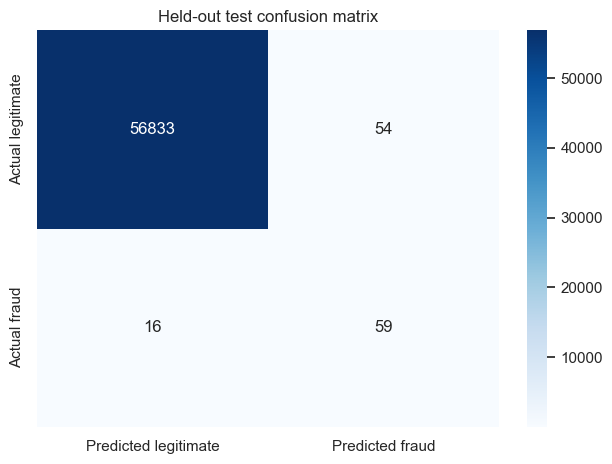

Top 1% capacity metrics on test:


,0
k,570.000000
flagged_fraction,0.010007
precision_at_k,0.114035
recall_at_k,0.866667
fraud_found,65.000000
total_fraud,75.000000


In [18]:
cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted legitimate", "Predicted fraud"],
            yticklabels=["Actual legitimate", "Actual fraud"])
plt.title("Held-out test confusion matrix")
plt.tight_layout()
plt.show()

print("Top 1% capacity metrics on test:")
display(pd.Series(top_k_metrics(y_test, test_proba, fraction=0.01)).to_frame())

## 5.5 Error analysis and segment diagnostics

Inspect false negatives and false positives, and look for changes in performance across time or transaction amount. Because the features are anonymized, meaningful domain explanations are limited.

Do not optimize repeatedly against the test-set segments. In production, define important segments before the final test, quantify uncertainty for small groups, and confirm changes on a new future period.

In [19]:
diagnostics = X_test.copy()
diagnostics["actual_fraud"] = np.asarray(y_test)
diagnostics["fraud_score"] = test_proba
diagnostics["predicted_fraud"] = test_pred
diagnostics["error_type"] = np.select(
    [
        (diagnostics["actual_fraud"] == 1) & (diagnostics["predicted_fraud"] == 0),
        (diagnostics["actual_fraud"] == 0) & (diagnostics["predicted_fraud"] == 1)
    ],
    ["false_negative", "false_positive"],
    default="correct"
)
display(diagnostics["error_type"].value_counts().to_frame("count"))
display(diagnostics.sort_values("fraud_score", ascending=False).head(10))

,count
error_type,
correct,56892
false_positive,54
false_negative,16


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V24,V25,V26,V27,V28,Amount,actual_fraud,fraud_score,predicted_fraud,error_type
274771,166198.0,-35.548539,-31.850484,-48.325589,15.304184,-113.743307,73.301626,120.589494,-27.347360,-3.872425,...,4.584549,4.554683,3.415636,31.612198,-15.430084,25691.16,0,1.0,1,false_positive
243699,152036.0,-4.320609,3.199939,-5.799736,6.502330,0.378479,-1.948246,-2.167860,-0.728207,-1.977238,...,-0.620072,0.642531,0.280717,-2.649107,0.533641,1.00,1,1.0,1,correct
243749,152058.0,-3.576362,3.299436,-7.460433,7.783634,-0.398549,-1.968441,-3.110476,-0.328404,-1.574363,...,-0.616962,-0.442811,0.359841,-2.651825,0.422184,1.00,1,1.0,1,correct
243848,152098.0,-4.124316,3.748597,-7.926507,7.763242,-0.769375,-2.031171,-3.474549,0.107121,-1.551352,...,-0.620601,-0.369688,0.367349,-2.664767,0.417101,1.00,1,1.0,1,correct
262826,160665.0,-0.417340,4.700055,-7.521767,7.671884,0.260821,-2.646693,-2.854432,0.958783,-4.588536,...,-0.742802,-0.312361,0.502575,0.821390,0.372379,0.77,1,1.0,1,correct
244004,152165.0,-4.673231,4.195976,-8.392423,7.743215,-1.138803,-2.094899,-3.839487,0.543053,-1.528448,...,-0.624399,-0.296289,0.374802,-2.678544,0.412368,1.00,1,1.0,1,correct
263274,160870.0,-0.644278,5.002352,-8.252739,7.756915,-0.216267,-2.751496,-3.358857,1.406268,-4.403852,...,-0.756170,-0.008172,0.532772,0.663970,0.192067,0.77,1,1.0,1,correct
244333,152307.0,-5.222968,4.641827,-8.858204,7.723502,-1.507035,-2.159484,-4.205164,0.979334,-1.505637,...,-0.628334,-0.222651,0.382208,-2.693036,0.407935,1.00,1,1.0,1,correct
262560,160537.0,0.567539,3.309385,-6.631268,6.394574,-0.054172,-2.396535,-2.792489,0.514811,-3.541780,...,-0.523271,0.645054,0.246466,0.902675,0.473571,4.69,1,1.0,1,correct
249963,154657.0,-0.679521,4.672553,-6.814798,7.143500,0.928654,-1.873013,-2.306689,0.993702,-4.944054,...,-1.120256,-0.073394,0.553530,0.760542,0.386742,0.77,1,1.0,1,correct


In [20]:
# Descriptive score/metric breakdown by transaction amount band.
amount_bins = pd.qcut(X_test["Amount"], q=5, duplicates="drop")
segment_df = pd.DataFrame({
    "amount_band": amount_bins.astype(str).to_numpy(),
    "actual": np.asarray(y_test),
    "pred": test_pred,
    "score": test_proba
})
segment_report = segment_df.groupby("amount_band", observed=False).apply(
    lambda g: pd.Series({
        "transactions": len(g),
        "fraud_rate": g["actual"].mean(),
        "precision": precision_score(g["actual"], g["pred"], zero_division=0),
        "recall": recall_score(g["actual"], g["pred"], zero_division=0),
        "mean_score": g["score"].mean()
    }),
    include_groups=False
).reset_index()
display(segment_report)

,amount_band,transactions,fraud_rate,precision,recall,mean_score
0,"(-0.001, 2.58]",11428.0,0.003063,0.492308,0.914286,0.076066
1,"(10.62, 29.99]",11510.0,0.000348,0.333333,0.250000,0.068933
2,"(2.58, 10.62]",11369.0,0.000880,0.666667,0.600000,0.056662
3,"(29.99, 86.56]",11265.0,0.000799,0.615385,0.888889,0.069239
4,"(86.56, 25691.16]",11390.0,0.001493,0.521739,0.705882,0.082641


## 5.6 Calibration and probability caveat

A model score can rank transactions well but still not represent a trustworthy probability. Calibration matters when scores are used in expected-loss calculations. Class weighting and oversampling can alter probability calibration; evaluate calibration on a representative, naturally distributed validation/calibration set.

Do not calibrate using the final test labels. If calibration is required, use a dedicated calibration set or a cross-validated calibration strategy that respects time.

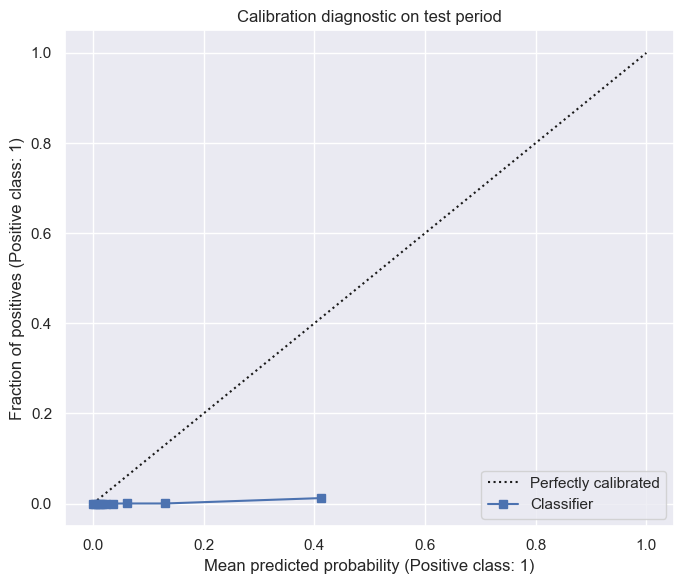

Brier score: 0.022732


In [21]:
from sklearn.calibration import CalibrationDisplay

fig, ax = plt.subplots(figsize=(7, 6))
CalibrationDisplay.from_predictions(y_test, test_proba, n_bins=10, strategy="quantile", ax=ax)
ax.set_title("Calibration diagnostic on test period")
plt.tight_layout()
plt.show()
print("Brier score:", round(float(brier_score_loss(y_test, test_proba)), 6))

# STEP 6 — Reproducibility and model management

## 6.1 Save the fitted pipeline, metadata, and reports

A model artifact should be accompanied by its feature contract, target definition, threshold, data source/version, code version, library versions, and actual evaluation metrics. A serialized Python object can execute code when loaded; only load artifacts from trusted sources.

The notebook writes local artifacts for learning. A production registry would add immutable versions, approval status, lineage, access control, and promotion history.

In [22]:
ARTIFACT_DIR = Path("artifacts")
REPORT_DIR = Path("reports")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = ARTIFACT_DIR / "fraud_pipeline.joblib"
METADATA_PATH = ARTIFACT_DIR / "model_metadata.json"
METRICS_PATH = REPORT_DIR / "test_metrics.json"
CV_PATH = REPORT_DIR / "validation_results.csv"

joblib.dump(model, MODEL_PATH)
validation_results.to_csv(CV_PATH, index=False)

metadata = {
    "project": "fraud-detection-portfolio",
    "target": TARGET,
    "positive_class": 1,
    "features": feature_columns,
    "selected_model": best_name,
    "decision_threshold": best_threshold,
    "threshold_cost_assumptions": {"false_negative_cost": FN_COST, "false_positive_cost": FP_COST},
    "dataset_source": DATA_URL,
    "dataset_rows": int(len(df)),
    "split_strategy": "time-ordered 60/20/20 by dataset Time",
    "random_state": RANDOM_STATE,
    "python_version": sys.version.split()[0],
    "pandas_version": pd.__version__,
    "scikit_learn_version": sklearn.__version__,
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "test_metrics": test_metrics,
    "limitations": [
        "Public benchmark, not production data",
        "Time is elapsed seconds rather than calendar timestamp",
        "Anonymized V features limit interpretability",
        "Threshold costs are illustrative"
    ]
}
METADATA_PATH.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
METRICS_PATH.write_text(json.dumps(test_metrics, indent=2), encoding="utf-8")

print("Saved artifacts:")
for p in [MODEL_PATH, METADATA_PATH, METRICS_PATH, CV_PATH]:
    print(p.resolve(), f"({p.stat().st_size:,} bytes)")

Saved artifacts:
/Users/vivek-18890/Python/learn_python/ml/14-projects/2-fraud-detection/notebook/artifacts/fraud_pipeline.joblib (3,290 bytes)
/Users/vivek-18890/Python/learn_python/ml/14-projects/2-fraud-detection/notebook/artifacts/model_metadata.json (1,631 bytes)
/Users/vivek-18890/Python/learn_python/ml/14-projects/2-fraud-detection/notebook/reports/test_metrics.json (362 bytes)
/Users/vivek-18890/Python/learn_python/ml/14-projects/2-fraud-detection/notebook/reports/validation_results.csv (319 bytes)


## 6.2 Optional MLflow tracking

Experiment tracking helps answer: which data, code, parameters, metrics, and artifact correspond to this model? Install `mlflow` if you want to run this section. Do not log secrets or raw sensitive transaction data.

In [23]:
try:
    import mlflow
    import mlflow.sklearn

    mlflow.set_experiment("fraud-detection-portfolio")
    with mlflow.start_run(run_name=best_name):
        mlflow.log_param("selected_model", best_name)
        mlflow.log_param("decision_threshold", best_threshold)
        mlflow.log_param("split_strategy", "time-ordered 60/20/20")
        mlflow.log_param("random_state", RANDOM_STATE)
        mlflow.log_metrics({
            k: float(v) for k, v in test_metrics.items()
            if isinstance(v, (int, float, np.integer, np.floating))
        })
        mlflow.log_artifact(str(METADATA_PATH))
        mlflow.log_artifact(str(CV_PATH))
        print("Logged run to MLflow.")
except ImportError:
    print("Optional dependency missing. Install with: python -m pip install mlflow")

Optional dependency missing. Install with: python -m pip install mlflow


# STEP 7 — ML-specific testing and quality gates

## 7.1 Test the prediction contract

Tests should verify schema, output shape, finite scores, probability range, serialization, and behavior under malformed inputs. Avoid tests that assert one exact model metric; such tests are brittle across library versions and data changes.

In [24]:
loaded_model = joblib.load(MODEL_PATH)
small_batch = X_test.iloc[:10].copy()
scores = loaded_model.predict_proba(small_batch)[:, 1]

assert TARGET not in small_batch.columns
assert list(small_batch.columns) == metadata["features"]
assert scores.shape == (len(small_batch),)
assert np.isfinite(scores).all()
assert ((scores >= 0) & (scores <= 1)).all()
assert 0 <= average_precision_score(y_test, test_proba) <= 1

print("Notebook prediction smoke checks passed.")

Notebook prediction smoke checks passed.


## 7.2 Repository-level test ideas

Automated tests in `tests/` should cover:
- target and label validation;
- feature schema validation;
- no target leakage into predictors;
- model artifact loading;
- prediction output shape and valid score range;
- malformed/missing/extra API fields;
- service health endpoints;
- data-quality and training gates.

CI should run unit tests on every change. More expensive training/evaluation can run on a schedule or a dedicated pipeline.

# STEP 8 — Deployment and serving

## 8.1 Architecture and batch-versus-online choice

- **Online API:** score a transaction synchronously when authorization needs an immediate answer.
- **Batch scoring:** score historical transactions for investigation or retrospective analysis.
- **Streaming:** score events continuously when the system architecture and latency requirements justify it.

Typical request flow: `payment service → authenticated API → schema validation → feature preparation → model → score/action → metrics`.

The model should be loaded once at service startup, not retrained for each request. A real payment decision system also needs strong availability, idempotency, timeout/fallback behavior, access controls, and carefully defined action semantics.

## 8.2 Minimal FastAPI serving template

The repository includes an API implementation. This notebook prints a minimal template for study. Save as `api.py` alongside `artifacts/` and install `fastapi` and `uvicorn` to run it.

The example returns a score and a threshold-based flag; it does **not** authorize or decline real payments. Never connect a tutorial model directly to real payment decisions.

In [25]:
fastapi_source = r'''
from pathlib import Path
import json
import joblib
import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, ConfigDict

BASE = Path(__file__).resolve().parent
model = joblib.load(BASE / "artifacts" / "fraud_pipeline.joblib")
metadata = json.loads((BASE / "artifacts" / "model_metadata.json").read_text())
features = metadata["features"]
threshold = float(metadata["decision_threshold"])

app = FastAPI(title="Fraud Risk Scoring API", version="1.0.0")

class ScoreRequest(BaseModel):
    model_config = ConfigDict(extra="forbid")
    features: dict

@app.get("/health/live")
def live():
    return {"status": "alive"}

@app.get("/health/ready")
def ready():
    return {"status": "ready", "model": metadata["selected_model"]}

@app.post("/score")
def score(request: ScoreRequest):
    missing = sorted(set(features) - set(request.features))
    extra = sorted(set(request.features) - set(features))
    if missing or extra:
        raise HTTPException(
            status_code=422,
            detail={"missing_features": missing, "unexpected_features": extra}
        )
    try:
        row = pd.DataFrame([{key: request.features[key] for key in features}])
        fraud_score = float(model.predict_proba(row)[:, 1][0])
        return {
            "fraud_score": fraud_score,
            "review_flag": int(fraud_score >= threshold),
            "threshold": threshold,
            "model_version": metadata.get("created_at_utc")
        }
    except Exception as exc:
        raise HTTPException(status_code=400, detail="Invalid feature values") from exc
'''
print(fastapi_source)


from pathlib import Path
import json
import joblib
import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, ConfigDict

BASE = Path(__file__).resolve().parent
model = joblib.load(BASE / "artifacts" / "fraud_pipeline.joblib")
metadata = json.loads((BASE / "artifacts" / "model_metadata.json").read_text())
features = metadata["features"]
threshold = float(metadata["decision_threshold"])

app = FastAPI(title="Fraud Risk Scoring API", version="1.0.0")

class ScoreRequest(BaseModel):
    model_config = ConfigDict(extra="forbid")
    features: dict

@app.get("/health/live")
def live():
    return {"status": "alive"}

@app.get("/health/ready")
def ready():
    return {"status": "ready", "model": metadata["selected_model"]}

@app.post("/score")
def score(request: ScoreRequest):
    missing = sorted(set(features) - set(request.features))
    extra = sorted(set(request.features) - set(features))
    if missing or extra:
        raise HTTPException(
         

## 8.3 Docker and CI/CD concepts

Containerization packages the service and dependencies; it does not guarantee a reproducible model by itself. Pin dependencies, identify the model artifact, scan images, run as non-root, and keep secrets out of the image.

A release pipeline should:
1. run linting and tests;
2. validate data contracts;
3. train and evaluate in a controlled job;
4. enforce quality gates;
5. build an immutable artifact/container;
6. deploy to staging and run smoke/load tests;
7. canary or shadow the new model;
8. promote or roll back based on predefined criteria.

In [26]:
dockerfile_example = r'''
FROM python:3.12-slim
WORKDIR /app
ENV PYTHONDONTWRITEBYTECODE=1 PYTHONUNBUFFERED=1
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY api.py .
COPY artifacts/ artifacts/
EXPOSE 8000
USER 10001
CMD ["uvicorn", "api:app", "--host", "0.0.0.0", "--port", "8000"]
'''
print(dockerfile_example)


FROM python:3.12-slim
WORKDIR /app
ENV PYTHONDONTWRITEBYTECODE=1 PYTHONUNBUFFERED=1
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY api.py .
COPY artifacts/ artifacts/
EXPOSE 8000
USER 10001
CMD ["uvicorn", "api:app", "--host", "0.0.0.0", "--port", "8000"]



# STEP 9 — Production monitoring

## 9.1 Separate service, data, drift, and model monitoring

- **Service:** request rate, error rate, p95/p99 latency, saturation, timeouts.
- **Data quality:** missing fields, invalid ranges, unexpected distributions, schema changes.
- **Data drift:** input distribution changes.
- **Concept drift:** the relationship between transaction features and fraud changes.
- **Model quality:** precision, recall, PR-AUC, calibration, and cost after labels mature.

Drift is a signal to investigate, not proof of degraded model quality and not an automatic retraining trigger.

In [27]:
def population_stability_index(reference, current, bins=10, eps=1e-6):
    """Numeric PSI drift signal. It is not a standalone model-quality metric."""
    ref = pd.Series(reference).dropna().astype(float)
    cur = pd.Series(current).dropna().astype(float)
    if ref.empty or cur.empty:
        raise ValueError("Reference and current samples must both be non-empty.")
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        return 0.0
    edges[0], edges[-1] = -np.inf, np.inf
    rc = pd.cut(ref, edges, include_lowest=True).value_counts(sort=False)
    cc = pd.cut(cur, edges, include_lowest=True).value_counts(sort=False)
    rp = np.clip(rc.to_numpy() / max(rc.sum(), 1), eps, None)
    cp = np.clip(cc.to_numpy() / max(cc.sum(), 1), eps, None)
    return float(np.sum((cp - rp) * np.log(cp / rp)))

print("Illustrative PSI, Amount train vs test:",
      round(population_stability_index(X_train["Amount"], X_test["Amount"]), 4))
print("This compares two dataset periods; do not interpret it as a production alert threshold.")

Illustrative PSI, Amount train vs test: 0.0093
This compares two dataset periods; do not interpret it as a production alert threshold.


## 9.2 Delayed labels and feedback loops

Fraud labels may arrive from investigations or chargebacks after days or weeks. A missing label is not necessarily a legitimate transaction; it may simply be immature.

Store, with appropriate retention and privacy controls:
- prediction time and model version;
- score and decision/action;
- approved feature snapshot or reproducible feature reference;
- outcome window and label maturity status;
- eventual label and source.

Evaluate only matured outcomes. Also account for selective labels: transactions that were blocked may never reveal whether they would have been fraudulent if approved. That can bias future training data.

# STEP 10 — Operations and continuous improvement

## 10.1 Release gates, retraining, rollback, incidents

Example release gates (adapt to business needs):
- schema and data-quality checks pass;
- no known leakage;
- future-period average precision beats a defined baseline;
- recall at review capacity meets target;
- false-positive rate and customer-impact metrics remain acceptable;
- calibration is acceptable if probabilities drive expected-loss calculations;
- latency, error rate, and memory targets pass;
- model artifact and code version are traceable.

Retrain when enough mature labels exist, a confirmed quality issue occurs, fraud patterns materially change, or a scheduled review finds the model stale. Do not promote automatically after training.

Keep the previous known-good model, define an owner for alerts, document safe fallback behavior, and rehearse rollback.

# STEP 11 — Performance, cost, privacy, and security

## 11.1 Latency, throughput, and resource cost

For a payment flow, p95/p99 latency can matter more than average latency. Measure under realistic concurrency and payload size. Include preprocessing, network overhead, model loading, and downstream calls in end-to-end latency.

Measure:
- throughput and p50/p95/p99 latency;
- CPU and memory;
- cold-start/model-loading time;
- error and timeout rates;
- cost per thousand or million scores;
- batch size and concurrency effects.

## 11.2 Security and responsible use

- Authenticate and authorize callers.
- Validate schema, numeric ranges, payload size, and rate limits.
- Avoid logging full transaction data or secrets.
- Restrict access to model artifacts and monitoring stores.
- Pin and scan dependencies and container images.
- Define data retention, purpose, and deletion rules.
- Treat model scores as risk signals, not proof of wrongdoing.
- Monitor false-positive impact and provide appropriate review/appeal paths.
- Document limitations, intended use, and prohibited use.

# STEP 12 — Documentation and interview readiness

## 12.1 Architecture summary

**Training path:** source data → schema/quality checks → time-ordered split → preprocessing pipeline → baseline/candidate models → validation threshold → future test evaluation → artifact + metadata.

**Serving path:** authenticated caller → request validation → model pipeline → fraud-risk score → downstream policy/review → service metrics and audit events.

**Monitoring path:** service health + input quality/drift + delayed outcome joins → evaluation gates → investigate/retrain/rollback decision.

## 12.2 Interview questions to practice

### Business and data
1. Why is accuracy misleading for rare fraud?
2. What are false-positive and false-negative costs in this use case?
3. How do you prevent target leakage?
4. Why use a temporal split rather than a random split?
5. What limitations does this anonymized benchmark have?
6. What is point-in-time correctness?

### Modeling and evaluation
7. Why average precision rather than accuracy?
8. How does class weighting affect training and calibration?
9. Compare Logistic Regression, Random Forest, and gradient boosting.
10. How does Isolation Forest work, and why are anomalies not necessarily fraud?
11. Why choose the threshold on validation data?
12. How do precision, recall, PR-AUC, ROC-AUC, and Brier score differ?
13. What is recall at a fixed review capacity?
14. How would you handle unseen fraud patterns?

### Production
15. What is the difference between drift and concept drift?
16. How do you monitor delayed labels?
17. What is selective-label bias when blocked transactions do not reveal their counterfactual outcome?
18. How would you design a low-latency scoring API?
19. What should be logged and what should not?
20. How would you roll back a bad model?
21. Why is retraining not the same as promotion?
22. How would you prove the model reduces fraud loss in a real business?

## 12.3 Two-minute project pitch — fill after execution

- **Problem and action:** ...
- **Dataset and limitations:** ...
- **Time split and leakage controls:** ...
- **Baseline and models compared:** ...
- **Actual validation/test metrics:** ...
- **Threshold/capacity trade-off:** ...
- **Error analysis finding:** ...
- **Serving/monitoring design:** ...
- **Limitations and next step:** ...

Never claim results, deployment, or business impact you did not measure.

## 12.4 Completion checklist

- [ ] Run every notebook cell from a fresh kernel.
- [ ] Record actual metrics and library versions.
- [ ] Inspect warnings and data source availability.
- [ ] Run repository tests and CI.
- [ ] Save and reload the artifact.
- [ ] Run the API locally and test malformed requests.
- [ ] Build the container and run a smoke test.
- [ ] Measure latency with a documented test setup.
- [ ] Document model, data, threshold, and limitations.
- [ ] Practice explaining trade-offs without reading notes.

**Completion standard:** understand why each decision was made, what can fail, and how you would verify that the system is safe and useful.